# Problem 1
## 1.

We have $n=12$ individuals, of which 3 have $C_1=1$ and 4 have $C_0=1$, thus
$$
\theta = \mathbb{E}(C_1) - \mathbb{E}(C_0) = \frac{3}{12} - \frac{4}{12} = -\frac{1}{12}.
$$

## 2.
In the treatment group there are 3 individuals with $C_1=1$ and in the control group there are 2 individuals with $C_0=1$. Both groups are size 6. The association is then
$$
\alpha = \mathbb{E}(Y \mid X=1) - \mathbb{E}(Y \mid X=0)= \frac{3}{6} - \frac{2}{6} = \frac{1}{6}.
$$

# Problem 2

For $Z=1$ we have
$$
\mathbb{P}(Y=1 \mid X=1, Z=1) = \frac{15}{40}=\frac{3}{8}
$$
and
$$
\mathbb{P}(Y=1 \mid X=0, Z=1) = \frac{5}{15}= \frac{1}{3},
$$
so $\mathbb{P}(Y=1 \mid X=1, Z=1) > \mathbb{P}(Y=1 \mid X=0, Z=1)$ regardless of $m$.
For $Z=0$ we have
$$
\mathbb{P}(Y=1 \mid X=1, Z=0) = \frac{20}{20+m}
$$
and
$$
\mathbb{P}(Y=1 \mid X=0, Z=0) = \frac{20}{30} = \frac{2}{3},
$$
so we get
$$
\begin{align*}
\mathbb{P}(Y=1 \mid X=1, Z=0) &> \mathbb{P}(Y=1 \mid X=0, Z=0) \\
\implies \frac{20}{20+m} &> \frac{2}{3} \\
\implies 2 \cdot (20+m) &< 60 \\
\implies 20 + m &< 30 \\
\implies m < 10.
\end{align*}
$$
Then we also need
$$
\begin{align*}
\mathbb{P}(Y=1 \mid X=1) &< \mathbb{P}(Y=1 \mid X=0)  \\
\implies \frac{35}{60+m} &< \frac{25}{45} \\
\implies 5\cdot (60+m) &> 9 \cdot 35 \\
\implies 60 + m &> 9 \cdot 7 \\
\implies m &> 3.
\end{align*}
$$
Thus the range of possible values of $m$ leading to Simpson's paradox is $3<m<10$, where $m\in \mathbb{N}$, i.e. $m\in \{4,5,6,7,8,9\}$.

# Problem 3
## 1.

In [1]:
import pandas as pd

data = pd.read_csv("./data/toy_missing.txt", sep="\t", names="X1 X2 X3 X4".split())
data

,X1,X2,X3,X4
0,-2.302,-0.831,NaN,NaN
1,1.091,1.272,0.205,1.419
2,-0.277,-0.116,-0.210,0.458
3,0.466,NaN,0.324,-0.559
4,0.020,1.013,-0.270,NaN
...,...,...,...,...
495,-0.658,NaN,NaN,-0.138
496,0.649,NaN,0.716,0.493
497,-0.157,-0.182,NaN,0.434
498,-1.772,-1.442,NaN,NaN


In [2]:
data.mean()

X1   -0.037666
X2   -0.079608
X3    0.388565
X4    0.436473
dtype: float64

The means differ significantly between the columns due to the amount of missing data.

## 2.

In [3]:
data.dropna().mean()

X1    0.557361
X2    0.451157
X3    0.474898
X4    0.582337
dtype: float64

When we drop the missing values the means are much closer to each other.

## 3.

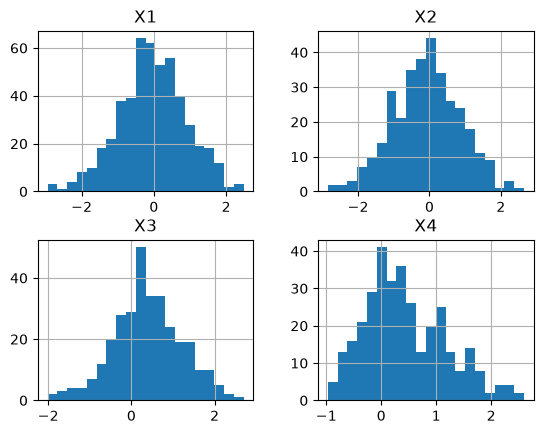

In [4]:
import matplotlib.pyplot as plt

data.hist(bins=20)
plt.show()

$X_1$ and $X_2$ have the same shape but $X_2$ has just fewer data. Variables $X_3$ and $X_4$ appear more and more right-skewed.

## 4.

In [5]:
data.dropna().corr() # complete

,X1,X2,X3,X4
X1,1.000000,0.667494,0.592397,0.633576
X2,0.667494,1.000000,0.340384,0.332393
X3,0.592397,0.340384,1.000000,0.338525
X4,0.633576,0.332393,0.338525,1.000000


In [6]:
data.corr() # pairwise complete

,X1,X2,X3,X4
X1,1.000000,0.805627,0.651844,0.671106
X2,0.805627,1.000000,0.312451,0.443313
X3,0.651844,0.312451,1.000000,0.388432
X4,0.671106,0.443313,0.388432,1.000000


## 5.

In [10]:
import statsmodels.formula.api as smf

for y in "X2 X3 X4".split():
    print(f"{y} ~ X1")
    results = smf.ols(f"{y} ~ X1", data=data).fit()
    print(results.summary())
    print("")

X2 ~ X1
                            OLS Regression Results                            
Dep. Variable:                     X2   R-squared:                       0.649
Model:                            OLS   Adj. R-squared:                  0.648
Method:                 Least Squares   F-statistic:                     610.3
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           5.06e-77
Time:                        17:00:19   Log-Likelihood:                -278.36
No. Observations:                 332   AIC:                             560.7
Df Residuals:                     330   BIC:                             568.3
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.0007      0.031     -0.022 

$X_2\sim X_1$ and $X_3\sim X_1$ are almost the same in terms of parameter values, but $X_4\sim X_1$ has a flatter slope.